# DSCI 552 — Homework 5
Decision Trees, LASSO, and Boosting

**Name:** __________Anita Hovsepian__________  
**GitHub Username:** __________anitahov__________  
**USC ID:** __________6881664760__________  


All data are loaded from the same directory as this notebook. Reproducible random seed: 42. Test data are never used to select hyperparameters.

## 1. Decision Trees as Interpretable Models

Import packages

In [23]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import StratifiedKFold, KFold, GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from xgboost import XGBRegressor
from IPython.display import display
BASE = Path.cwd()
SEED = 42
sns.set_theme(style='whitegrid')

### (a) Obtain Data

The file `diagnosis.data` is UTF-16 encoded, with a decimal comma in temperature and tab-separated symptom/diagnosis fields. The final two columns are simultaneous binary targets (multi-output classification).

In [24]:
import pandas as pd
from pathlib import Path

BASE = Path.cwd()

# Download the dataset from GitHub if it is missing
if not (BASE / 'diagnosis.data').exists():
    import urllib.request
    url = "https://raw.githubusercontent.com/anitahov/Hovsepian_Anita_HW5/main/diagnosis.data"
    urllib.request.urlretrieve(url, BASE / 'diagnosis.data')

# Load diagnosis dataset
diagnosis = pd.read_csv(
    BASE / 'diagnosis.data',
    encoding='utf-16',
    sep='\t',
    header=None,
    engine='python'
)

diagnosis.columns = [
    'temperature', 'nausea', 'lumbar_pain',
    'urine_pushing', 'micturition_pains',
    'burning_urethra', 'bladder_inflammation',
    'renal_pelvis_nephritis'
]

diagnosis['temperature'] = (
    diagnosis['temperature'].astype(str)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

for col in diagnosis.columns[1:]:
    diagnosis[col] = (
        diagnosis[col].astype(str)
        .str.strip()
        .str.lower()
        .map({'yes': 1, 'no': 0})
    )

assert not diagnosis.isna().any().any(), "Unexpected unparsed diagnosis values"

X_dt = diagnosis.iloc[:, :6]
y_dt = diagnosis.iloc[:, 6:]

print("Data dimensions:", diagnosis.shape)
display(diagnosis.head())


Data dimensions: (120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,renal_pelvis_nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

Full tree: 11 nodes, 6 leaves, depth 4
Training exact-match accuracy: 1.0


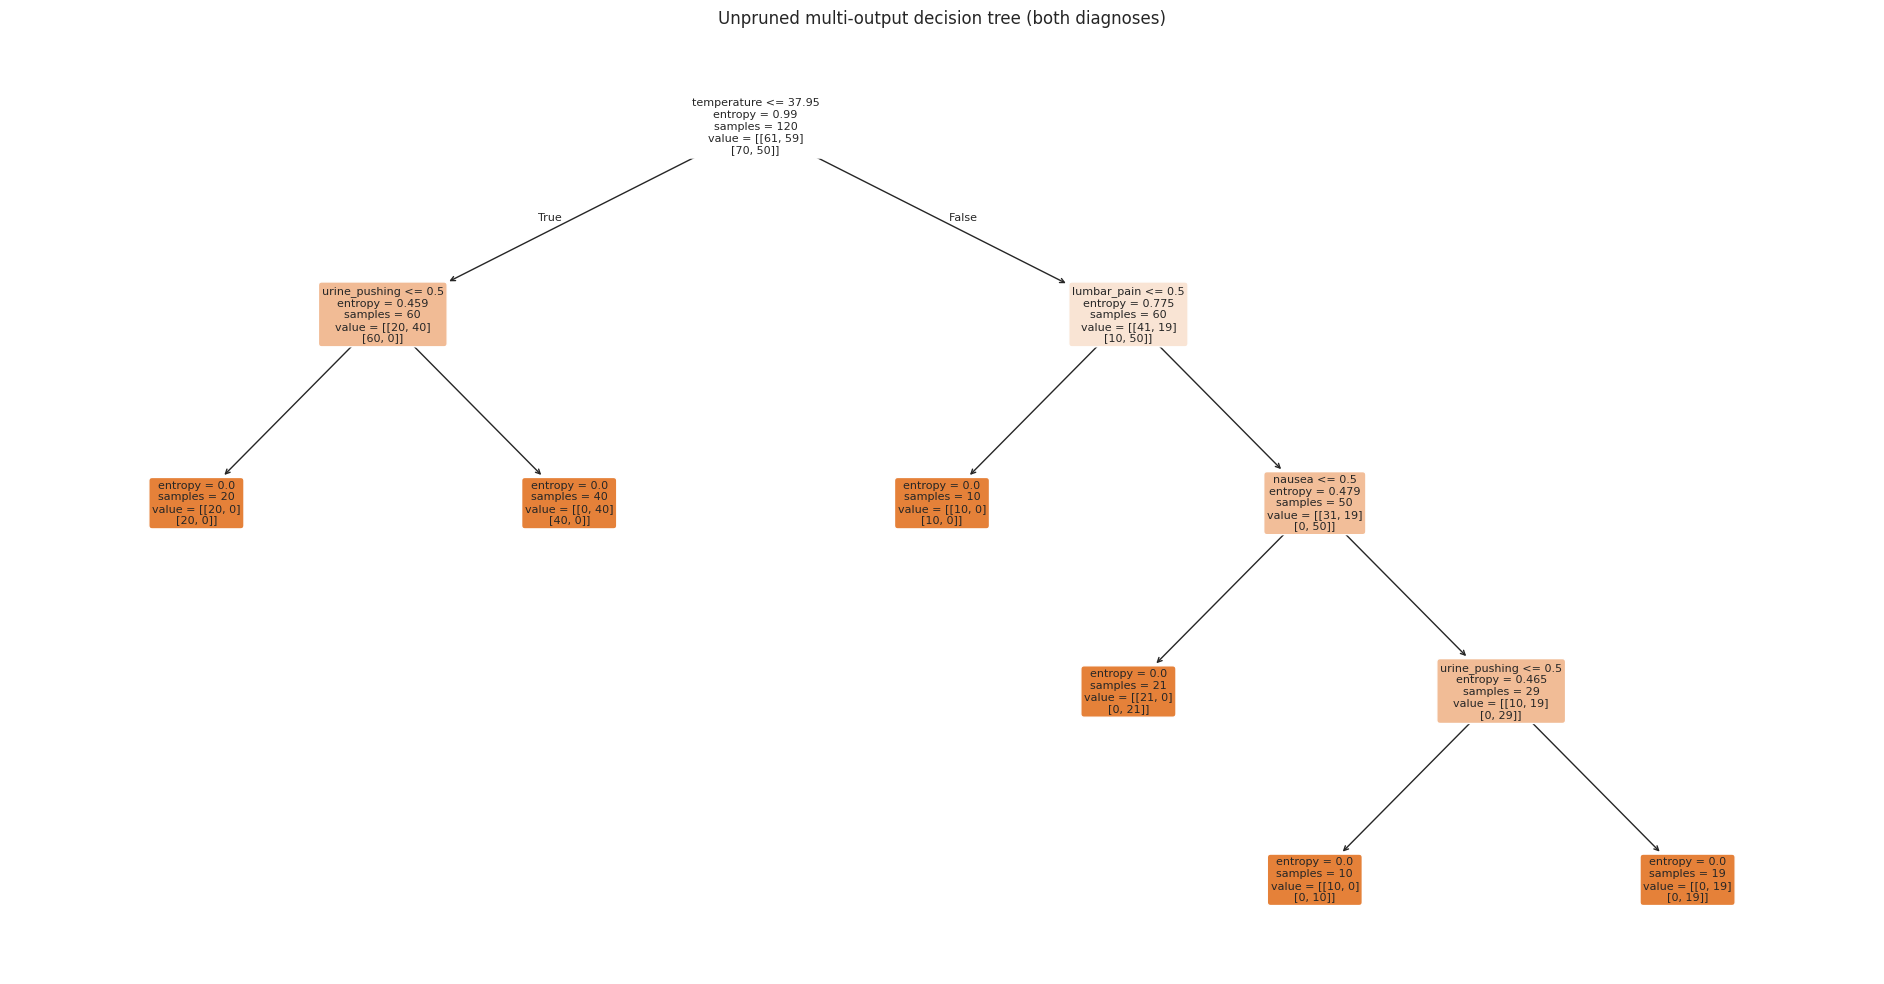

In [25]:
full_tree = DecisionTreeClassifier(random_state=SEED, criterion='entropy')
full_tree.fit(X_dt, y_dt)
print(f'Full tree: {full_tree.tree_.node_count} nodes, {full_tree.get_n_leaves()} leaves, depth {full_tree.get_depth()}')
print('Training exact-match accuracy:', accuracy_score(y_dt, full_tree.predict(X_dt)))
plt.figure(figsize=(19, 10))
plot_tree(full_tree, feature_names=X_dt.columns, filled=True, rounded=True, fontsize=8)
plt.title('Unpruned multi-output decision tree (both diagnoses)')
plt.tight_layout(); plt.show()

### (c) Convert the decision rules into IF–THEN rules
Each root-to-leaf path is one rule. A leaf predicts both binary diagnoses. The code prints the complete rule set without rounding away the underlying threshold decisions.

In [26]:
def if_then_rules(model, feature_names, output_names):
    t = model.tree_
    def walk(node, conditions):
        if t.children_left[node] == t.children_right[node]:
            # Predictions for each output are the majority class at the leaf.
            pred = model.classes_
            labels = []
            for k, name in enumerate(output_names):
                cls = pred[k][np.argmax(t.value[node, k, :len(pred[k])])]
                labels.append(f'{name}={"yes" if cls == 1 else "no"}')
            print('IF ' + (' AND '.join(conditions) if conditions else 'TRUE') + ' THEN ' + ', '.join(labels)
                  + f' [n={t.n_node_samples[node]}]')
        else:
            name = feature_names[t.feature[node]]
            cut = t.threshold[node]
            walk(t.children_left[node], conditions + [f'{name} <= {cut:.3f}'])
            walk(t.children_right[node], conditions + [f'{name} > {cut:.3f}'])
    walk(0, [])
print('Rules for the unpruned tree:')
if_then_rules(full_tree, list(X_dt.columns), list(y_dt.columns))

Rules for the unpruned tree:
IF temperature <= 37.950 AND urine_pushing <= 0.500 THEN bladder_inflammation=no, renal_pelvis_nephritis=no [n=20]
IF temperature <= 37.950 AND urine_pushing > 0.500 THEN bladder_inflammation=yes, renal_pelvis_nephritis=no [n=40]
IF temperature > 37.950 AND lumbar_pain <= 0.500 THEN bladder_inflammation=no, renal_pelvis_nephritis=no [n=10]
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea <= 0.500 THEN bladder_inflammation=no, renal_pelvis_nephritis=yes [n=21]
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea > 0.500 AND urine_pushing <= 0.500 THEN bladder_inflammation=no, renal_pelvis_nephritis=yes [n=10]
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea > 0.500 AND urine_pushing > 0.500 THEN bladder_inflammation=yes, renal_pelvis_nephritis=yes [n=19]


### (d) Cost-complexity pruning
Select `ccp_alpha` using five-fold cross-validation on the available diagnosis data, using **exact-match accuracy** for both outputs. The simplest tree within one standard error of the best mean CV score is selected (one-standard-error rule). This prioritizes interpretability without using training accuracy to choose complexity.

Original tree leaves: 6
Pruned tree leaves: 6
Selected alpha: 0.0
Cross-validation accuracy: 1.0
Training accuracy: 1.0


,alpha,cv_accuracy,cv_se,leaves
0,0.000000,1.000000,0.000000,6
1,0.099796,0.891667,0.044876,4
2,0.188093,0.783333,0.042492,3
3,0.229574,0.658333,0.035843,2
4,0.372575,0.333333,0.080147,1


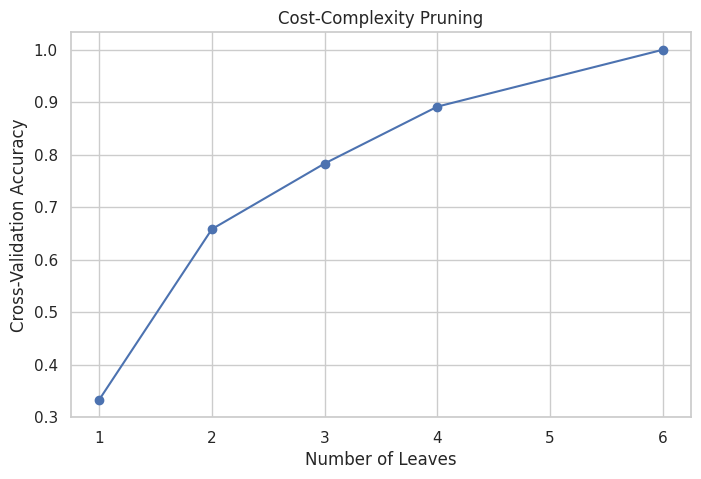

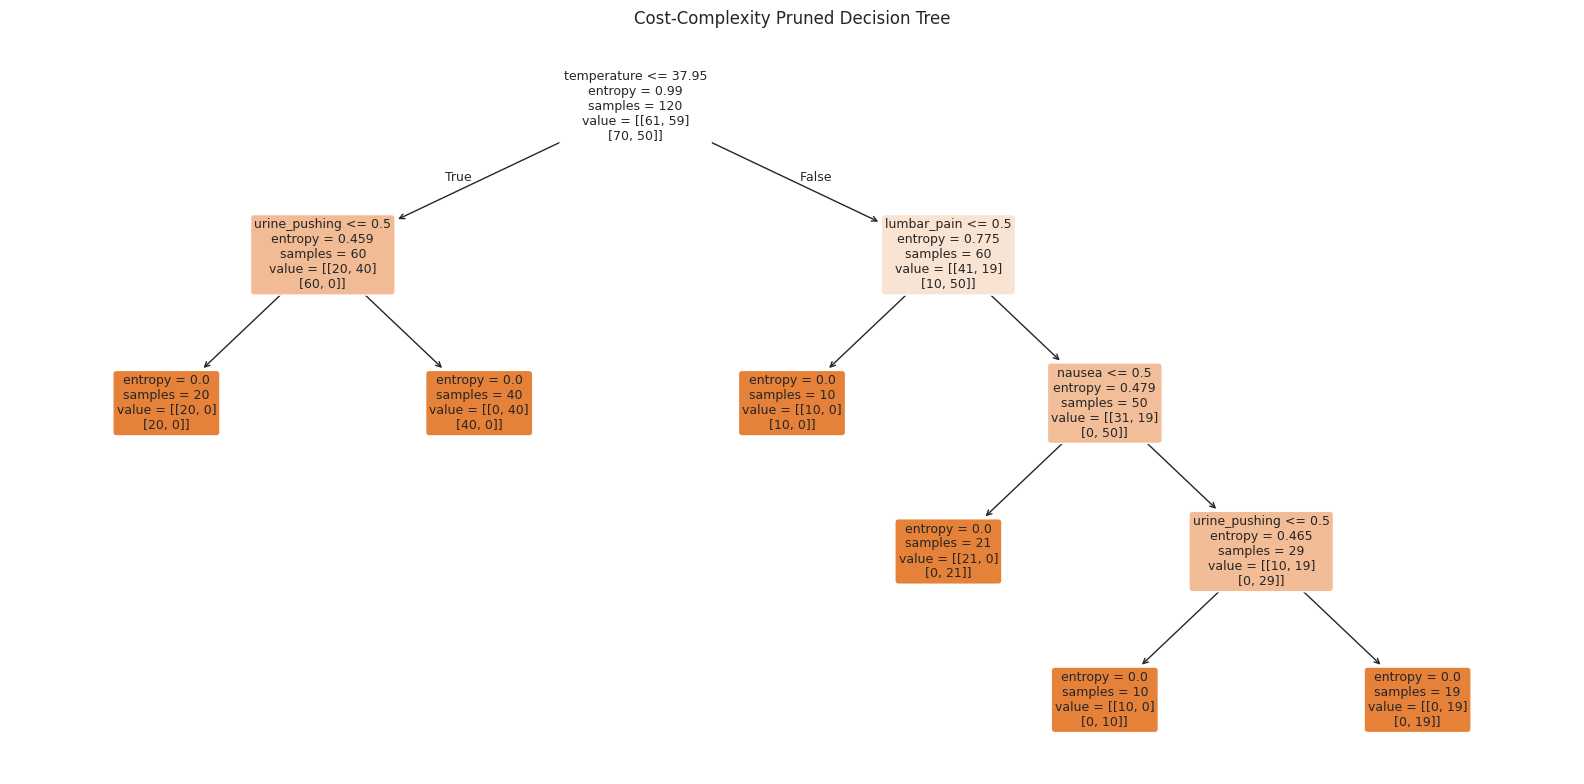

Pruned Decision Tree Rules:
IF temperature <= 37.950 AND urine_pushing <= 0.500 THEN bladder_inflammation=no, renal_pelvis_nephritis=no [n=20]
IF temperature <= 37.950 AND urine_pushing > 0.500 THEN bladder_inflammation=yes, renal_pelvis_nephritis=no [n=40]
IF temperature > 37.950 AND lumbar_pain <= 0.500 THEN bladder_inflammation=no, renal_pelvis_nephritis=no [n=10]
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea <= 0.500 THEN bladder_inflammation=no, renal_pelvis_nephritis=yes [n=21]
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea > 0.500 AND urine_pushing <= 0.500 THEN bladder_inflammation=no, renal_pelvis_nephritis=yes [n=10]
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea > 0.500 AND urine_pushing > 0.500 THEN bladder_inflammation=yes, renal_pelvis_nephritis=yes [n=19]


In [27]:

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import KFold, cross_val_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Obtain cost-complexity pruning parameters
path = full_tree.cost_complexity_pruning_path(X_dt, y_dt)
alphas = np.unique(path.ccp_alphas)

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

results = []

for alpha in alphas:
    model = DecisionTreeClassifier(
        criterion='entropy',
        random_state=SEED,
        ccp_alpha=float(alpha)
    )

    scores = cross_val_score(
        model, X_dt, y_dt,
        cv=cv,
        scoring='accuracy'
    )

    model.fit(X_dt, y_dt)

    results.append({
        'alpha': alpha,
        'cv_accuracy': scores.mean(),
        'cv_se': scores.std(ddof=1) / np.sqrt(len(scores)),
        'leaves': model.get_n_leaves()
    })

pruning_results = pd.DataFrame(results)

# Apply the one-standard-error rule
best = pruning_results.loc[
    pruning_results['cv_accuracy'].idxmax()
]

cutoff = best['cv_accuracy'] - best['cv_se']

eligible = pruning_results[
    pruning_results['cv_accuracy'] >= cutoff
]

# Select the simplest eligible tree
chosen = eligible.sort_values(
    ['leaves', 'alpha'],
    ascending=[True, False]
).iloc[0]

pruned_tree = DecisionTreeClassifier(
    criterion='entropy',
    random_state=SEED,
    ccp_alpha=float(chosen['alpha'])
)

pruned_tree.fit(X_dt, y_dt)

print("Original tree leaves:", full_tree.get_n_leaves())
print("Pruned tree leaves:", pruned_tree.get_n_leaves())
print("Selected alpha:", chosen['alpha'])
print("Cross-validation accuracy:", chosen['cv_accuracy'])
print("Training accuracy:", pruned_tree.score(X_dt, y_dt))

display(pruning_results)

# Plot cross-validation results
plt.figure(figsize=(8, 5))
plt.plot(
    pruning_results['leaves'],
    pruning_results['cv_accuracy'],
    'o-'
)
plt.xlabel('Number of Leaves')
plt.ylabel('Cross-Validation Accuracy')
plt.title('Cost-Complexity Pruning')
plt.grid(True)
plt.show()

# Plot pruned decision tree
plt.figure(figsize=(16, 8))
plot_tree(
    pruned_tree,
    feature_names=X_dt.columns,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title('Cost-Complexity Pruned Decision Tree')
plt.tight_layout()
plt.show()

# Display IF-THEN rules
print("Pruned Decision Tree Rules:")
if_then_rules(
    pruned_tree,
    list(X_dt.columns),
    list(y_dt.columns)
)


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data
The provided `communities.names` file supplies feature names. As instructed, the first 1,495 observations are training data and all remaining observations are test data. The target is `ViolentCrimesPerPop`.

In [28]:

import pandas as pd
import numpy as np
import re
import urllib.request
from pathlib import Path

BASE = Path.cwd()

# Download missing datasets from GitHub
github_url = "https://raw.githubusercontent.com/anitahov/Hovsepian_Anita_HW5/main/"

for filename in ['communities.names', 'communities.data']:
    file_path = BASE / filename

    if not file_path.exists():
        urllib.request.urlretrieve(
            github_url + filename,
            file_path
        )

# Read feature names
names_text = (BASE / 'communities.names').read_text(
    encoding='latin-1'
)

attributes = re.findall(
    r'^@attribute\s+(\S+)',
    names_text,
    flags=re.I | re.M
)

# Load Communities and Crime dataset
raw = pd.read_csv(
    BASE / 'communities.data',
    header=None,
    na_values='?'
)

assert len(attributes) == raw.shape[1], (
    len(attributes), raw.shape[1]
)

raw.columns = attributes

# Remove nonpredictive identifiers
nonpredictive = [
    'state', 'county', 'community',
    'communityname', 'fold'
]

target = 'ViolentCrimesPerPop'

features = raw.drop(
    columns=nonpredictive + [target]
).apply(pd.to_numeric, errors='coerce')

y = pd.to_numeric(
    raw[target],
    errors='coerce'
)

assert y.notna().all()

# First 1495 rows for training
X_train_raw = features.iloc[:1495].copy()
X_test_raw = features.iloc[1495:].copy()

y_train = y.iloc[:1495].copy()
y_test = y.iloc[1495:].copy()

print("Full dataset:", raw.shape)
print("Training:", X_train_raw.shape)
print("Testing:", X_test_raw.shape)
print("Ignored nonpredictive identifiers:", nonpredictive)
print("Missing feature cells:", features.isna().sum().sum())

display(raw.head())


Full dataset: (1994, 128)
Training: (1495, 122)
Testing: (499, 122)
Ignored nonpredictive identifiers: ['state', 'county', 'community', 'communityname', 'fold']
Missing feature cells: 36851


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values
Remove columns that have no observed values in the **training set**, then impute the remaining missing entries with their training-set median. This avoids test-set leakage. All downstream models use these same imputed features; the CV models use preprocessing pipelines where appropriate.

In [29]:
empty_cols = X_train_raw.columns[X_train_raw.isna().all()].tolist()
X_train_raw = X_train_raw.drop(columns=empty_cols)
X_test_raw = X_test_raw.drop(columns=empty_cols)
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X_train_raw.columns, index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns, index=X_test_raw.index)
X_all = pd.concat([X_train, X_test]).sort_index()
print('Dropped all-missing training columns:', empty_cols)
print('Retained predictors:', X_train.shape[1], '| Remaining missing:', X_all.isna().sum().sum())
# Keep the original (unimputed) data for leakage-free cross-validation.
X_train_cv = X_train_raw.copy()
X_test_cv = X_test_raw.copy()


Dropped all-missing training columns: []
Retained predictors: 122 | Remaining missing: 0


### (c) Plot a correlation matrix

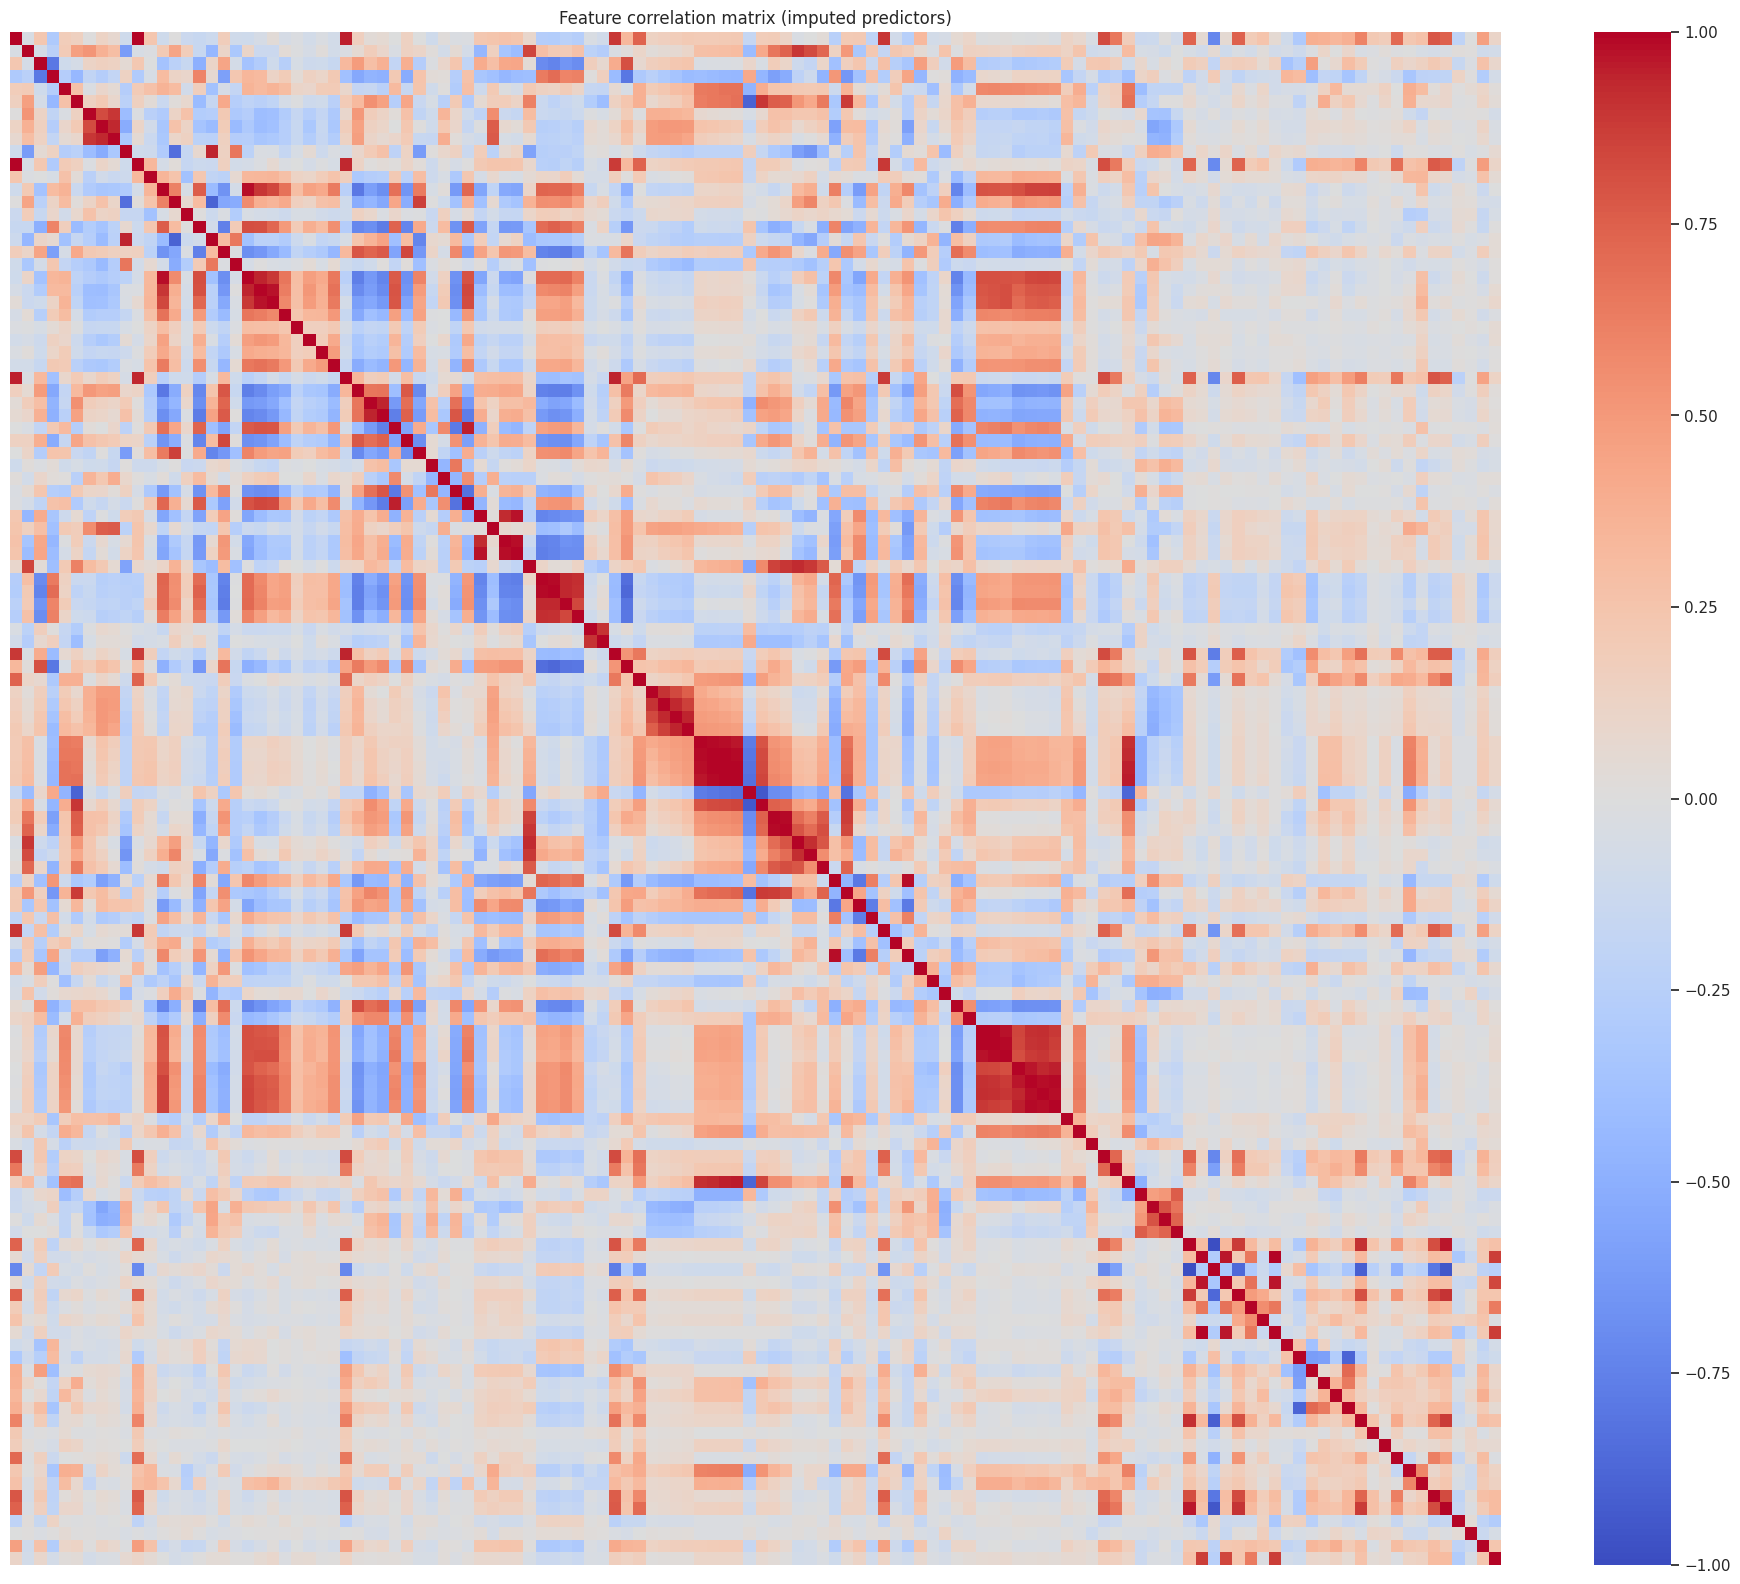

Interpretation: groups of correlated features indicate potential multicollinearity; regularization and PCR may help.


In [30]:
corr = X_all.corr()
plt.figure(figsize=(19, 16))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False)
plt.title('Feature correlation matrix (imputed predictors)'); plt.tight_layout(); plt.show()
print('Interpretation: groups of correlated features indicate potential multicollinearity; regularization and PCR may help.')

### (d) Calculate the Coefficient of Variation CV

In [31]:
means = X_all.mean()
sd = X_all.std(ddof=1)
cv_values = sd / means.abs().replace(0, np.nan)
cv_table = pd.DataFrame({'mean':means, 'sample_sd':sd, 'CV':cv_values}).sort_values('CV', ascending=False)
print('CV = sample standard deviation / |sample mean|; undefined when mean is zero.')
display(cv_table)

CV = sample standard deviation / |sample mean|; undefined when mean is zero.


,mean,sample_sd,CV
PctPolicAsian,0.018375,0.100105,5.447835
NumStreet,0.022778,0.100400,4.407702
NumInShelters,0.029438,0.102607,3.485481
NumIlleg,0.036294,0.108671,2.994196
NumImmig,0.030060,0.087189,2.900497
...,...,...,...
NumKindsDrugsSeiz,0.567768,0.081320,0.143227
RacialMatchCommPol,0.723506,0.091814,0.126902
LemasPctPolicOnPatr,0.750176,0.088376,0.117807
PctPolicWhite,0.763114,0.089838,0.117726


### (e) Scatter plots and box plots for highest CV features

floor(sqrt(122)) = 11; selected features: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


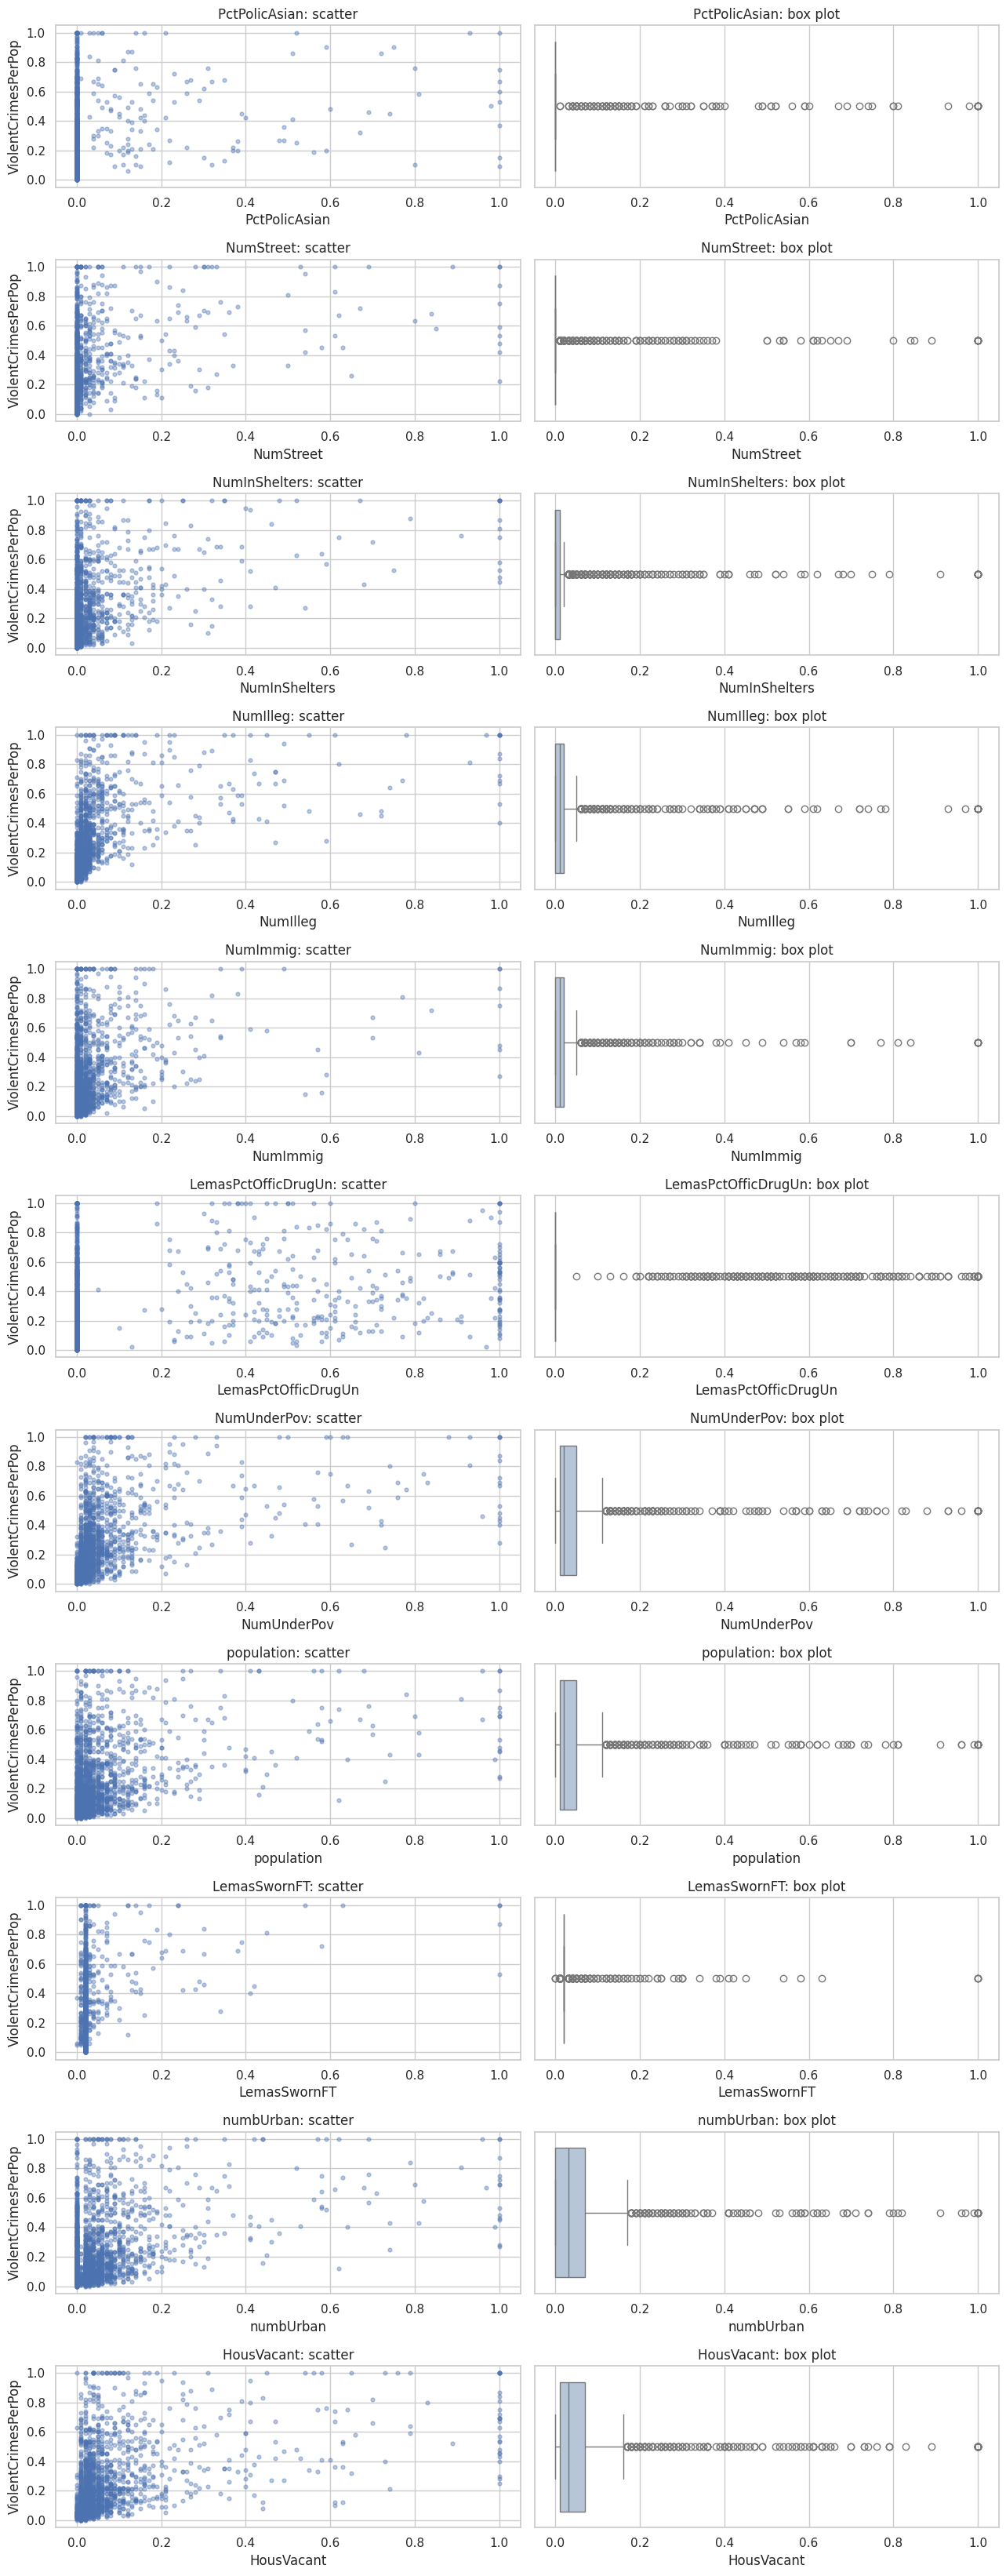

Conclusion: plots can suggest associations, skewness, and outliers, but cannot establish statistical significance, causality, or independent predictive contribution. High CV alone does not imply predictive usefulness.


In [32]:
k = int(np.floor(np.sqrt(X_all.shape[1])))
top_features = cv_table['CV'].replace([np.inf,-np.inf], np.nan).dropna().head(k).index.tolist()
print(f'floor(sqrt({X_all.shape[1]})) = {k}; selected features:', top_features)
fig, axes = plt.subplots(k, 2, figsize=(13, 3*k))
for i, feature in enumerate(top_features):
    axes[i,0].scatter(X_all[feature], y, alpha=.4, s=12)
    axes[i,0].set(xlabel=feature, ylabel=target, title=f'{feature}: scatter')
    sns.boxplot(x=X_all[feature], ax=axes[i,1], color='lightsteelblue')
    axes[i,1].set(title=f'{feature}: box plot', xlabel=feature)
plt.tight_layout(); plt.show()
print('Conclusion: plots can suggest associations, skewness, and outliers, but cannot establish statistical significance, causality, or independent predictive contribution. High CV alone does not imply predictive usefulness.')

### (f) Fit a linear model

In [33]:
ols = LinearRegression().fit(X_train, y_train)
ols_mse = mean_squared_error(y_test, ols.predict(X_test))
print(f'OLS test MSE: {ols_mse:.6f}')

OLS test MSE: 0.017966


### (g) Fit a ridge regression model

In [34]:
from sklearn.linear_model import Ridge
folds = KFold(n_splits=5, shuffle=True, random_state=SEED)
alphas_reg = np.logspace(-5, 3, 80)
ridge_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')),
                       ('scale', StandardScaler()), ('model', Ridge())])
ridge_search = GridSearchCV(ridge_pipe, {'model__alpha': alphas_reg}, cv=folds,
                            scoring='neg_mean_squared_error', n_jobs=-1)
ridge_search.fit(X_train_cv, y_train)
ridge = ridge_search.best_estimator_
ridge_mse = mean_squared_error(y_test, ridge.predict(X_test_cv))
print('Ridge chosen lambda:', ridge_search.best_params_['model__alpha'])
print(f'Ridge test MSE: {ridge_mse:.6f}')

Ridge chosen lambda: 154.8365256585499
Ridge test MSE: 0.017346


### (h) Fit a LASSO model

In [35]:
from sklearn.linear_model import Lasso
lasso_alphas = np.logspace(-5, -1, 60)

def fit_lasso(scale):
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale', StandardScaler()))
    steps.append(('model', Lasso(max_iter=30000, random_state=SEED)))
    search = GridSearchCV(Pipeline(steps), {'model__alpha': lasso_alphas}, cv=folds,
                          scoring='neg_mean_squared_error', n_jobs=-1)
    search.fit(X_train_cv, y_train)
    estimator = search.best_estimator_
    mse = mean_squared_error(y_test, estimator.predict(X_test_cv))
    selected = X_train_cv.columns[np.abs(estimator.named_steps['model'].coef_) > 1e-8].tolist()
    return search, estimator, mse, selected

lasso_raw_search, lasso_raw, lasso_raw_mse, raw_selected = fit_lasso(False)
lasso_scaled_search, lasso_scaled, lasso_scaled_mse, scaled_selected = fit_lasso(True)
for title, search, mse, selected in [('Without standardization', lasso_raw_search, lasso_raw_mse, raw_selected),
                                      ('With standardization', lasso_scaled_search, lasso_scaled_mse, scaled_selected)]:
    print('\nLASSO', title)
    print('Selected lambda:', search.best_params_['model__alpha'])
    print(f'Test MSE: {mse:.6f}')
    print('Number of selected variables:', len(selected))
    print('Selected variables:', selected)
print('\nBetter test MSE:', 'standardized' if lasso_scaled_mse < lasso_raw_mse else 'unstandardized' if lasso_raw_mse < lasso_scaled_mse else 'tie')


LASSO Without standardization
Selected lambda: 0.0001215474250076286
Test MSE: 0.017623
Number of selected variables: 74
Selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOw

### (i) Fit a PCR model

Selected number of components M: 60
PCR test MSE: 0.018350


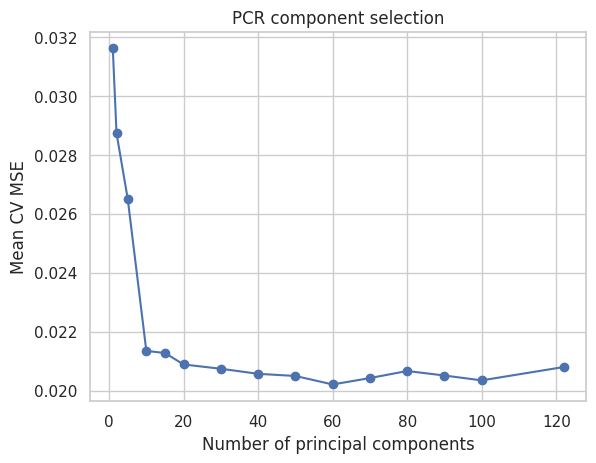

In [36]:
# Choose M using training-only CV, with imputation/scaling fitted within each fold.
max_components = X_train_cv.shape[1]
component_grid = sorted(set([1, 2, 5, 10, 15, 20, 30, 40, 50, 60, 70, 80, 90, 100, max_components]))
component_grid = [m for m in component_grid if m <= max_components]
pcr = Pipeline([('imputer', SimpleImputer(strategy='median')),
                ('scale', StandardScaler()), ('pca', PCA(svd_solver='full')),
                ('reg', LinearRegression())])
pcr_search = GridSearchCV(pcr, {'pca__n_components': component_grid}, cv=folds,
                          scoring='neg_mean_squared_error', n_jobs=-1)
pcr_search.fit(X_train_cv, y_train)
pcr_mse = mean_squared_error(y_test, pcr_search.predict(X_test_cv))
print('Selected number of components M:', pcr_search.best_params_['pca__n_components'])
print(f'PCR test MSE: {pcr_mse:.6f}')
plt.plot(component_grid, -pcr_search.cv_results_['mean_test_score'], 'o-')
plt.xlabel('Number of principal components'); plt.ylabel('Mean CV MSE')
plt.title('PCR component selection'); plt.show()

### (j) Fit a boosting tree

In [37]:
# The assignment expressly permits XGBoost; reg_alpha is its L1 leaf-weight penalty.
boost = Pipeline([('imputer', SimpleImputer(strategy='median')),
                  ('model', XGBRegressor(objective='reg:squarederror', n_estimators=250,
                          max_depth=3, learning_rate=0.05, subsample=0.9,
                          colsample_bytree=0.9, reg_lambda=1, random_state=SEED,
                          n_jobs=1, tree_method='hist'))])
boost_search = GridSearchCV(boost, {'model__reg_alpha': [0, 0.001, 0.01, 0.1, 1, 10]},
                            cv=folds, scoring='neg_mean_squared_error', n_jobs=1)
boost_search.fit(X_train_cv, y_train)
boost_mse = mean_squared_error(y_test, boost_search.predict(X_test_cv))
print('Selected XGBoost alpha (reg_alpha):', boost_search.best_params_['model__reg_alpha'])
print(f'XGBoost test MSE: {boost_mse:.6f}')
summary = pd.DataFrame({'Model': ['OLS', 'Ridge', 'LASSO (raw)', 'LASSO (standardized)', 'PCR', 'XGBoost'],
                        'Test MSE': [ols_mse, ridge_mse, lasso_raw_mse, lasso_scaled_mse, pcr_mse, boost_mse]})
display(summary.sort_values('Test MSE').reset_index(drop=True))
print('Lower held-out test MSE is better.')

Selected XGBoost alpha (reg_alpha): 0.001
XGBoost test MSE: 0.016289


,Model,Test MSE
0,XGBoost,0.016289
1,Ridge,0.017346
2,LASSO (raw),0.017623
3,LASSO (standardized),0.017742
4,OLS,0.017966
5,PCR,0.018350


Lower held-out test MSE is better.


Interpretation and submission notes
The table above reports held-out test mean squared error for each regression method; lower values indicate better prediction. Ridge, LASSO, PCR, and XGBoost hyperparameters are selected using five-fold cross-validation on the training observations only. The original first-1495/rest split is preserved. The correlation and CV analyses are descriptive and cannot by themselves establish statistical significance. The decision-tree pruning result may legitimately retain the unpruned tree if it gives the best cross-validation performance.

Reproducibility: Keep diagnosis.data, communities.data, and communities.names in the repository with this notebook. Required packages: numpy, pandas, matplotlib, seaborn, scikit-learn, and xgboost. If running in Colab, the data-loading cells retrieve missing files from the repository.